# Végső projekt — előkészítés: szállodai foglalások lemondása

**Adat:** Hotel Booking Demand — két portugál szálloda (egy lisszaboni városi szálloda és egy algarvei üdülőszálloda) foglalásai, 2015 júliusa és 2017 augusztusa között érkezőkkel.
**Forrás:** N. Antonio, A. de Almeida, L. Nunes (2019): *Hotel booking demand datasets*, Data in Brief 22, 41–49 (CC BY).

## A kérdés

**Előre jelezhető-e, hogy egy foglalást le fognak mondani?** A célváltozó az `is_canceled` (1 = lemondta vagy nem jelent meg, 0 = megérkezett).

Ez a szállodák bevételmenedzsmentjének egyik fő kérdése. Ha a szálloda előre tudja, mely foglalások maradnak el valószínűleg, akkor túlfoglalhat, emlékeztetőt vagy előleg-ajánlatot küldhet, és jobban tervezheti a személyzetet.

**Miért ez az adat:**
1. **Elég megfigyelés:** kb. 119 ezer foglalás, jóval a 20 ezres küszöb felett.
2. **Érdekel a probléma:** kereskedelem és marketing szakos hallgatóként a foglalási csatornák, az árazás és a vendégviselkedés kapcsolata közvetlenül a szakterületem.
3. **A magyarázó változók magyarázzák a célt:** az alábbi ábrákon jól látszik, hogy a lemondás aránya erősen függ a foglalás időzítésétől, a csatornától és a vendég kéréseitől.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv("hotel_bookings.csv" if os.path.exists("hotel_bookings.csv") else URL, na_values=["NULL"])
print("Sorok és oszlopok száma:", df.shape)
df.head()

Sorok és oszlopok száma: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## A változók

| Csoport | Oszlopok |
|---|---|
| Foglalás és időzítés | `lead_time` (hány nappal az érkezés előtt foglaltak), az érkezés éve, hónapja, hete, napja |
| Tartózkodás | hétvégi és hétköznapi éjszakák, felnőttek, gyerekek, babák, ellátás (`meal`) |
| Csatorna és vendég | értékesítési szegmens, értékesítési csatorna, utazási iroda, cég, vendégtípus, ország, visszatérő vendég, korábbi foglalások és lemondások |
| Ár és feltételek | átlagos napi ár (`adr`), előleg típusa, foglalt szobatípus |
| Kérések | különleges kérések száma, parkolóhely, módosítások, várólistán töltött napok |
| Kimenet | `reservation_status` (lemondva / megérkezett / nem jelent meg) és dátuma |

## Ábrák

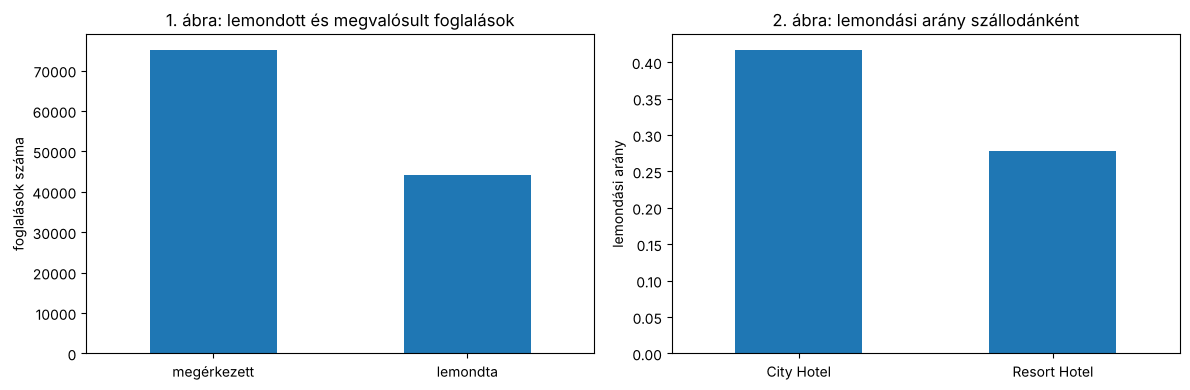

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["is_canceled"].map({0: "megérkezett", 1: "lemondta"}).value_counts().plot.bar(ax=ax[0], rot=0)
ax[0].set(title="1. ábra: lemondott és megvalósult foglalások", ylabel="foglalások száma", xlabel="")
df.groupby("hotel")["is_canceled"].mean().plot.bar(ax=ax[1], rot=0)
ax[1].set(title="2. ábra: lemondási arány szállodánként", ylabel="lemondási arány", xlabel="")
plt.tight_layout(); plt.show()

**Megfigyelés:** a foglalások jelentős részét, nagyjából minden harmadikat lemondják. A városi szállodában gyakoribb a lemondás, mint az üdülőszállodában. A két osztály nem nagyon kiegyensúlyozatlan, ez kedvező a modellezéshez.

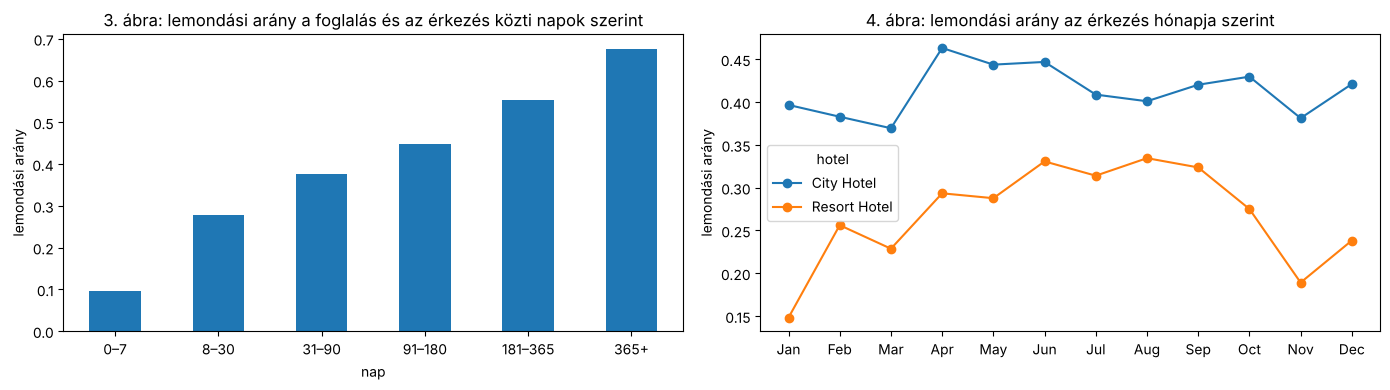

In [3]:
MONTHS = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October",
          "November", "December"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
bins = [-1, 7, 30, 90, 180, 365, 1000]
labels = ["0–7", "8–30", "31–90", "91–180", "181–365", "365+"]
df.groupby(pd.cut(df["lead_time"], bins, labels=labels), observed=True)["is_canceled"].mean().plot.bar(ax=ax[0], rot=0)
ax[0].set(title="3. ábra: lemondási arány a foglalás és az érkezés közti napok szerint", xlabel="nap", ylabel="lemondási arány")
df.groupby(["arrival_date_month", "hotel"])["is_canceled"].mean().unstack().reindex(MONTHS).plot(ax=ax[1], marker="o")
ax[1].set(title="4. ábra: lemondási arány az érkezés hónapja szerint", xlabel="", ylabel="lemondási arány")
ax[1].set_xticks(range(12)); ax[1].set_xticklabels([m[:3] for m in MONTHS])
plt.tight_layout(); plt.show()

**Megfigyelés:** a legerősebb összefüggés a foglalás időzítésével van. Minél korábban foglal valaki, annál valószínűbb, hogy lemondja: az utolsó héten foglalók ritkán, az egy évnél korábban foglalók nagy része lemond. A lemondási arány hónaponként is változik, tehát van szezonalitás, és a két szálloda mintázata eltér.

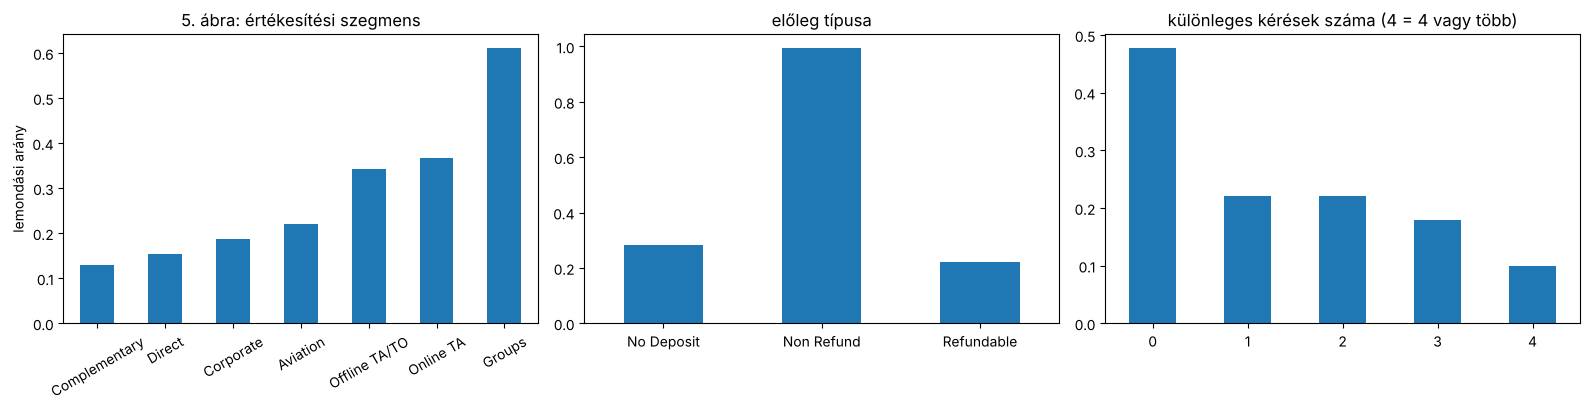

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
seg = df.groupby("market_segment")["is_canceled"].agg(["mean", "size"])
seg[seg["size"] >= 100]["mean"].sort_values().plot.bar(ax=ax[0], rot=30)
ax[0].set(title="5. ábra: értékesítési szegmens", ylabel="lemondási arány", xlabel="")
df.groupby("deposit_type")["is_canceled"].mean().plot.bar(ax=ax[1], rot=0)
ax[1].set(title="előleg típusa", xlabel="")
df.groupby(df["total_of_special_requests"].clip(upper=4))["is_canceled"].mean().plot.bar(ax=ax[2], rot=0)
ax[2].set(title="különleges kérések száma (4 = 4 vagy több)", xlabel="")
plt.tight_layout(); plt.show()

**Megfigyelés:**
- **Szegmens:** a csoportos foglalásokat mondják le a leggyakrabban, a közvetlen és a céges foglalásokat a legritkábban.
- **Különleges kérések:** aki kér valamit (pl. kiságyat, emeletet), az ritkábban mond le, mert valószínűleg komolyabban tervez.
- **Előleg:** meglepő módon a vissza nem térítendő előleggel foglalt szobák szinte mind lemondásra kerülnek. Ez ellentmond a józan észnek, és a végső projektben közelebbről meg kell vizsgálni. Lehet, hogy utazási irodák előre lefoglalt szobakontingenseiről van szó.

## Első észrevételek az adatról

- **Hiányzó értékek:** az utazási iroda és a cég oszlopa sokszor üres. Ez valószínűleg azt jelenti, hogy a foglalás nem irodán vagy cégen keresztül érkezett, tehát a hiánynak jelentése van.
- **Ismétlődő sorok:** sok sor teljesen azonos. Ezek valószínűleg csoportos foglalások egyes szobái. A modellezésnél figyelni kell, hogy egy csoport ne kerüljön szét a tanító és a teszt halmaz között.
- **Furcsa értékek:** van néhány foglalás vendég nélkül, 0 vagy negatív árral, illetve egy kiugróan magas napi árral. Ezeket a tisztításnál kezelni kell.
- **Szivárgás:** a `reservation_status` maga a válasz (lemondva vagy megérkezett), ezért nem lehet magyarázó változó. Néhány más oszlop (pl. a kiosztott szobatípus, az ország) valószínűleg csak érkezéskor derül ki, ezeket is ellenőrizni kell.

## Terv a végső projektre

1. Tisztítás: a furcsa értékek és az ismétlődő sorok kezelése, a szivárgó oszlopok kizárása.
2. Időrendi vágás: a múltbeli foglalásokból jósolni a későbbiekre.
3. Modellek összehasonlítása (pl. logisztikus regresszió, döntési fa, Random Forest, XGBoost).
4. Üzleti kérdés: hogyan használhatja a szálloda az előrejelzést a túlfoglalási döntéseknél.

**Kérdések a visszajelzéshez:**
- A vissza nem térítendő előleges (csoportos) foglalásokat külön kezeljem vagy hagyjam ki?
- Érdemes-e a két szállodára külön modellt építeni?